Saving Iris(5).csv to Iris(5).csv
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Best K: 9
Best accuracy: 0.9736842105263158


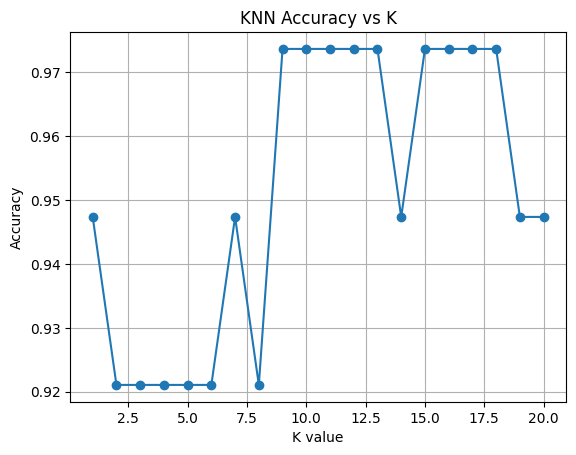

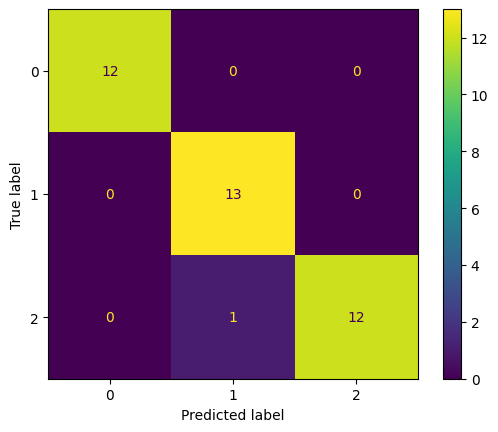

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))
print(df.head())

target = next(c for c in df.columns
              if c.lower() in ["species", "class"])
X = df.select_dtypes(include=np.number)
X = X.drop(columns=[c for c in X.columns if c.lower() == "id"],
           errors="ignore")
y = LabelEncoder().fit_transform(df[target].astype(str))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

scores = []
for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    scores.append(accuracy_score(y_test, model.predict(X_test)))

best_k = np.argmax(scores) + 1
print("Best K:", best_k)
print("Best accuracy:", scores[best_k - 1])

plt.plot(range(1, 21), scores, marker="o")
plt.xlabel("K value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.grid()
plt.show()

model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train, y_train)
pred = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()